# Xem nhật ký huấn luyện (training log) của H1 và H2
Notebook phụ, **chỉ đọc** các file mà notebook chính `00_MASTER_Causal_PGM_Educational_Intervention.ipynb` đã lưu — không huấn luyện lại, không thay đổi kết quả nào.

| Nguồn | Nội dung |
| :--- | :--- |
| `artifacts/checkpoints/h1_seed<s>_early_stop.pt` | H1 **có** early stopping (bản dùng trong Tables A–C): trọng số + log loss TRAIN/VAL từng epoch |
| `artifacts/checkpoints/h1_seed<s>_no_early_stop.pt` | H1 **không** early stopping (chạy đủ 150 epoch): trọng số + log từng epoch |
| `artifacts/graphs/h2_dag_seed<s>.json` | H2: số vòng ngoài, $h(W)$ cuối, bảng chọn ngưỡng $\tau$ trên VALIDATION |
| `artifacts/tables/Table_Overfit_Train_Val_Test.csv` | AUROC / Accuracy / log-loss trên TRAIN, VAL, TEST |
| `artifacts/tables/Table_H1_Early_Stopping.csv` | So sánh H1 có / không early stopping |

Chạy notebook chính trước (Restart & Run All) để các file trên tồn tại.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Tìm thư mục gốc dự án (nơi có artifacts/), dù mở notebook từ notebook/ hay từ thư mục gốc
GOC = Path.cwd()
while not (GOC / 'artifacts' / 'checkpoints').exists() and GOC != GOC.parent:
    GOC = GOC.parent
CKPT, GRAPHS, TABLES = GOC / 'artifacts' / 'checkpoints', GOC / 'artifacts' / 'graphs', GOC / 'artifacts' / 'tables'
SEEDS = [42, 43, 44, 45, 46]
print('Thư mục dự án:', GOC)


def doc_log_h1(seed: int, ban: str) -> dict:
    """Đọc phần 'meta' (cấu hình + log từng epoch) trong checkpoint H1; ban = 'early_stop' hoặc 'no_early_stop'."""
    return torch.load(CKPT / f'h1_seed{seed}_{ban}.pt', map_location='cpu', weights_only=False)['meta']


LOG = {(s, b): doc_log_h1(s, b) for s in SEEDS for b in ('early_stop', 'no_early_stop')}
m = LOG[(42, 'early_stop')]
print('Kiến trúc H1:', m['architecture'])
print('Tối ưu     :', m['optimizer'], '| số tham số =', m['n_params'], '| cha của Y =', m['parents'])

Thư mục dự án: E:\01_Research_Study_Master\04_Probabilistic_GrModel
Kiến trúc H1: Linear(4,32)-BN-ReLU-Dropout(0.2)-Linear(32,16)-ReLU-Linear(.,1)
Tối ưu     : Adam(lr=0.005, weight_decay=0.0001), batch=64 | số tham số = 769 | cha của Y = ['T', 'Z2', 'Z3', 'Z5']


## 1. Log H1 từng epoch — kiểu Keras
Mỗi dòng là một epoch: BCE trung bình trên TRAIN (đo khi dropout đang bật) và BCE trên VALIDATION (chế độ đánh giá). ★ là epoch có val BCE thấp nhất — trọng số được giữ lại khi có early stopping.

In [2]:
def in_log_h1(seed: int, ban: str, so_dong_cuoi: int = None) -> None:
    """In log từng epoch của một bản H1; so_dong_cuoi giới hạn số dòng in ở cuối (cho bản chạy đủ 150 epoch)."""
    m = LOG[(seed, ban)]
    tot = m['best_epoch'] + 1
    n = len(m['train_loss'])
    print(f"===== H1 seed {seed} | {'CÓ' if m.get('early_stopping', ban == 'early_stop') else 'KHÔNG'} early stopping "
          f"| chạy {n} epoch | epoch tốt nhất = {tot} (val BCE = {m['best_val_bce']:.4f}) =====")
    cac_epoch = range(1, n + 1)
    if so_dong_cuoi and n > 2 * so_dong_cuoi:
        cac_epoch = list(range(1, so_dong_cuoi + 1)) + [None] + list(range(n - so_dong_cuoi + 1, n + 1))
    for k in cac_epoch:
        if k is None:
            print('   ...')
            continue
        tl, vl = m['train_loss'][k - 1], m['val_loss'][k - 1]
        print(f"Epoch {k:>3}/150 - train_bce: {tl:.4f} - val_bce: {vl:.4f}{'  ★ best' if k == tot else ''}")
    if ban == 'early_stop' and n < 150:
        print(f"Early stopping: {n - tot} epoch liên tiếp không cải thiện val_bce -> dừng, khôi phục trọng số epoch {tot}.")
    print()


for s in SEEDS:
    in_log_h1(s, 'early_stop')

===== H1 seed 42 | CÓ early stopping | chạy 18 epoch | epoch tốt nhất = 3 (val BCE = 0.5267) =====
Epoch   1/150 - train_bce: 0.5441 - val_bce: 0.5315
Epoch   2/150 - train_bce: 0.5093 - val_bce: 0.5321
Epoch   3/150 - train_bce: 0.5050 - val_bce: 0.5267  ★ best
Epoch   4/150 - train_bce: 0.5042 - val_bce: 0.5350
Epoch   5/150 - train_bce: 0.5063 - val_bce: 0.5299
Epoch   6/150 - train_bce: 0.4996 - val_bce: 0.5291
Epoch   7/150 - train_bce: 0.5071 - val_bce: 0.5296
Epoch   8/150 - train_bce: 0.5032 - val_bce: 0.5303
Epoch   9/150 - train_bce: 0.5006 - val_bce: 0.5313
Epoch  10/150 - train_bce: 0.5036 - val_bce: 0.5329
Epoch  11/150 - train_bce: 0.5070 - val_bce: 0.5375
Epoch  12/150 - train_bce: 0.5034 - val_bce: 0.5337
Epoch  13/150 - train_bce: 0.5028 - val_bce: 0.5303
Epoch  14/150 - train_bce: 0.5010 - val_bce: 0.5332
Epoch  15/150 - train_bce: 0.5001 - val_bce: 0.5330
Epoch  16/150 - train_bce: 0.5032 - val_bce: 0.5300
Epoch  17/150 - train_bce: 0.5024 - val_bce: 0.5320
Epoch  18

In [3]:
# Bản KHÔNG early stopping: in 10 epoch đầu và 10 epoch cuối của từng seed
for s in SEEDS:
    in_log_h1(s, 'no_early_stop', so_dong_cuoi=10)

===== H1 seed 42 | KHÔNG early stopping | chạy 150 epoch | epoch tốt nhất = 3 (val BCE = 0.5267) =====
Epoch   1/150 - train_bce: 0.5441 - val_bce: 0.5315
Epoch   2/150 - train_bce: 0.5093 - val_bce: 0.5321
Epoch   3/150 - train_bce: 0.5050 - val_bce: 0.5267  ★ best
Epoch   4/150 - train_bce: 0.5042 - val_bce: 0.5350
Epoch   5/150 - train_bce: 0.5063 - val_bce: 0.5299
Epoch   6/150 - train_bce: 0.4996 - val_bce: 0.5291
Epoch   7/150 - train_bce: 0.5071 - val_bce: 0.5296
Epoch   8/150 - train_bce: 0.5032 - val_bce: 0.5303
Epoch   9/150 - train_bce: 0.5006 - val_bce: 0.5313
Epoch  10/150 - train_bce: 0.5036 - val_bce: 0.5329
   ...
Epoch 141/150 - train_bce: 0.5015 - val_bce: 0.5303
Epoch 142/150 - train_bce: 0.4991 - val_bce: 0.5312
Epoch 143/150 - train_bce: 0.4988 - val_bce: 0.5338
Epoch 144/150 - train_bce: 0.5007 - val_bce: 0.5329
Epoch 145/150 - train_bce: 0.4968 - val_bce: 0.5308
Epoch 146/150 - train_bce: 0.4986 - val_bce: 0.5320
Epoch 147/150 - train_bce: 0.4983 - val_bce: 0.536

## 2. Đường cong loss H1: có và không có early stopping

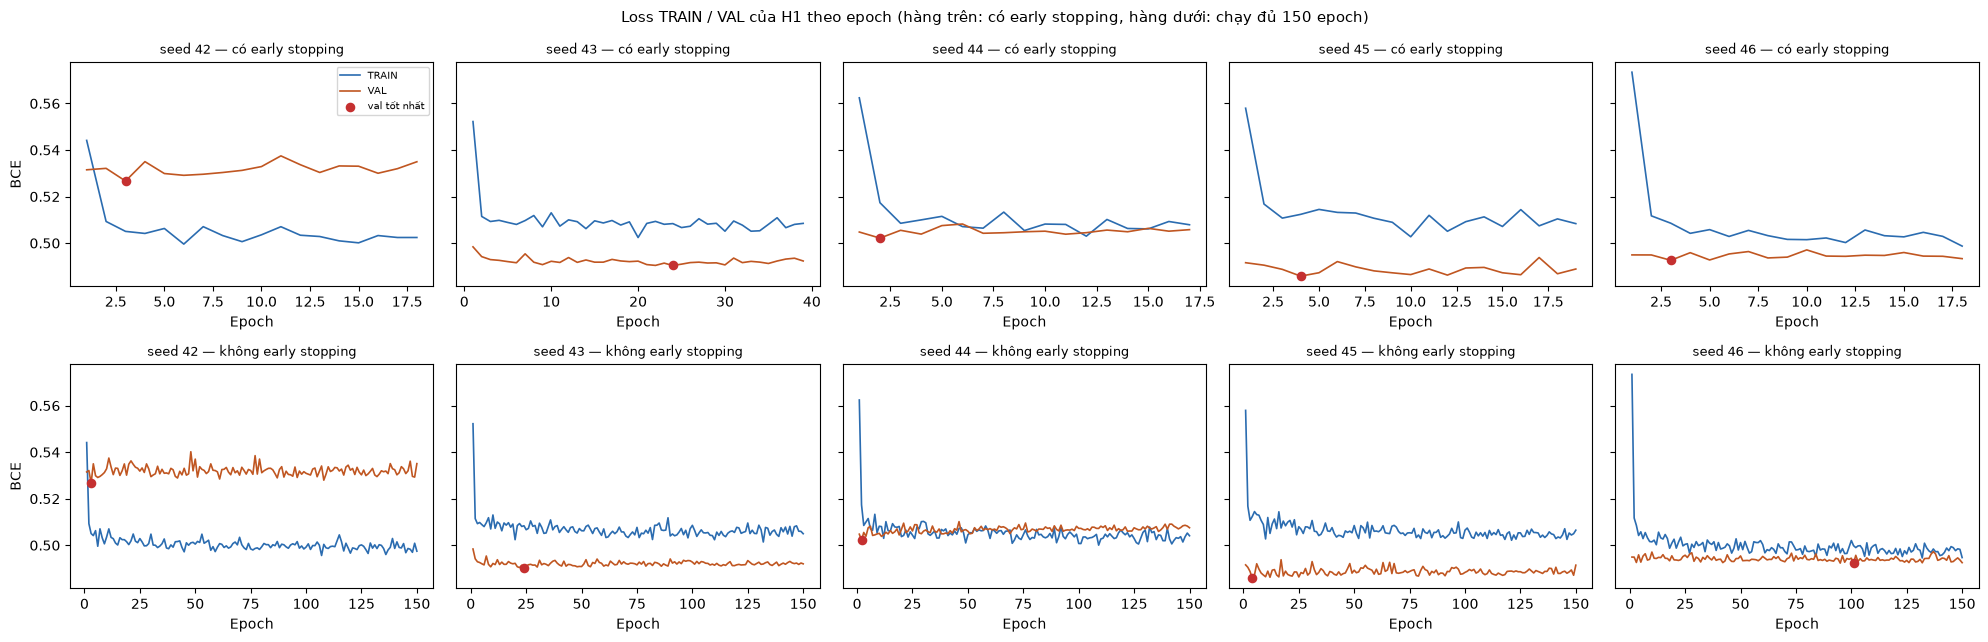

In [4]:
fig, axes = plt.subplots(2, len(SEEDS), figsize=(4 * len(SEEDS), 6.5), sharey=True)
for j, s in enumerate(SEEDS):
    for i, ban in enumerate(['early_stop', 'no_early_stop']):
        m = LOG[(s, ban)]
        ep = np.arange(1, len(m['train_loss']) + 1)
        ax = axes[i, j]
        ax.plot(ep, m['train_loss'], color='#2b6cb0', lw=1.2, label='TRAIN')
        ax.plot(ep, m['val_loss'], color='#c05621', lw=1.2, label='VAL')
        ax.scatter([m['best_epoch'] + 1], [m['best_val_bce']], color='#c53030', s=35, zorder=5, label='val tốt nhất')
        ax.set_title(f"seed {s} — {'có' if ban == 'early_stop' else 'không'} early stopping", fontsize=9)
        ax.set_xlabel('Epoch')
axes[0, 0].set_ylabel('BCE')
axes[1, 0].set_ylabel('BCE')
axes[0, 0].legend(fontsize=7)
fig.suptitle('Loss TRAIN / VAL của H1 theo epoch (hàng trên: có early stopping, hàng dưới: chạy đủ 150 epoch)', fontsize=11)
fig.tight_layout()
plt.show()

In [5]:
# Tóm tắt nhanh từ log: loss tại epoch cuối và tại epoch tốt nhất
dong = []
for (s, ban), m in LOG.items():
    dong.append({'seed': s, 'bản': ban, 'số_epoch': len(m['train_loss']), 'epoch_tốt_nhất': m['best_epoch'] + 1,
                 'val_bce_tốt_nhất': round(m['best_val_bce'], 4),
                 'train_bce_epoch_cuối': round(m['train_loss'][-1], 4), 'val_bce_epoch_cuối': round(m['val_loss'][-1], 4)})
display(pd.DataFrame(dong).sort_values(['bản', 'seed']).reset_index(drop=True))

,seed,bản,số_epoch,epoch_tốt_nhất,val_bce_tốt_nhất,train_bce_epoch_cuối,val_bce_epoch_cuối
0,42,early_stop,18,3,0.5267,0.5024,0.5350
1,43,early_stop,39,24,0.4904,0.5085,0.4923
2,44,early_stop,17,2,0.5021,0.5079,0.5058
3,45,early_stop,19,4,0.4858,0.5084,0.4889
4,46,early_stop,18,3,0.4926,0.4987,0.4933
5,42,no_early_stop,150,3,0.5267,0.4975,0.5351
6,43,no_early_stop,150,24,0.4904,0.5050,0.4920
7,44,no_early_stop,150,2,0.5021,0.5041,0.5075
8,45,no_early_stop,150,4,0.4858,0.5065,0.4915
9,46,no_early_stop,150,101,0.4923,0.4947,0.4925


## 3. Log H2 (NOTEARS-MLP) từng vòng ngoài
$H_2$ không dùng epoch. Mỗi **vòng ngoài** của augmented Lagrangian gồm 300 bước Adam; sau mỗi vòng, nếu $h(W)$ chưa giảm đủ thì tăng hệ số phạt. Dừng khi $h(W) < 10^{-6}$ (đồ thị không còn chu trình) hoặc hết 12 vòng. Log lấy từ `h_history`, `recon_history` trong `artifacts/graphs/h2_dag_seed<s>.json`.

In [6]:
H2 = {s: json.load(open(GRAPHS / f'h2_dag_seed{s}.json', encoding='utf-8')) for s in SEEDS}
for s in SEEDS:
    d = H2[s]
    print(f"===== H2 seed {s} | lambda_L1 = {d['lambda_l1']} | {d['outer_iters']} vòng ngoài | hội tụ = {d['converged']} =====")
    for k, (h, rc) in enumerate(zip(d['h_history'], d['recon_history']), start=1):
        print(f"Vòng {k:>2}/12 - h(W): {h:.2e} - recon_loss: {rc:.4f}{'  -> hội tụ (h < 1e-6)' if h < 1e-6 else ''}")
    print(f"Ngưỡng tau chọn trên VAL = {d['tau_selected_on_val']} -> {len(d['edges'])} cạnh | max|W| ở ô bị cấm = {d['forbidden_weight_max']}")
    print()

===== H2 seed 42 | lambda_L1 = 0.0001 | 7 vòng ngoài | hội tụ = True =====
Vòng  1/12 - h(W): 3.23e-02 - recon_loss: 0.4364
Vòng  2/12 - h(W): 5.53e-03 - recon_loss: 0.4361
Vòng  3/12 - h(W): 1.03e-03 - recon_loss: 0.4364
Vòng  4/12 - h(W): 1.54e-04 - recon_loss: 0.4374
Vòng  5/12 - h(W): 1.89e-05 - recon_loss: 0.4414
Vòng  6/12 - h(W): 1.66e-06 - recon_loss: 0.4484
Vòng  7/12 - h(W): 3.29e-07 - recon_loss: 0.4918  -> hội tụ (h < 1e-6)
Ngưỡng tau chọn trên VAL = 0.1 -> 8 cạnh | max|W| ở ô bị cấm = 0.0

===== H2 seed 43 | lambda_L1 = 0.0001 | 8 vòng ngoài | hội tụ = True =====
Vòng  1/12 - h(W): 2.73e-02 - recon_loss: 0.4379
Vòng  2/12 - h(W): 5.38e-03 - recon_loss: 0.4377
Vòng  3/12 - h(W): 1.04e-03 - recon_loss: 0.4379
Vòng  4/12 - h(W): 1.57e-04 - recon_loss: 0.4391
Vòng  5/12 - h(W): 1.91e-05 - recon_loss: 0.4430
Vòng  6/12 - h(W): 4.59e-06 - recon_loss: 0.4468
Vòng  7/12 - h(W): 1.00e-06 - recon_loss: 0.4500
Vòng  8/12 - h(W): 1.89e-07 - recon_loss: 0.4540  -> hội tụ (h < 1e-6)
Ngư

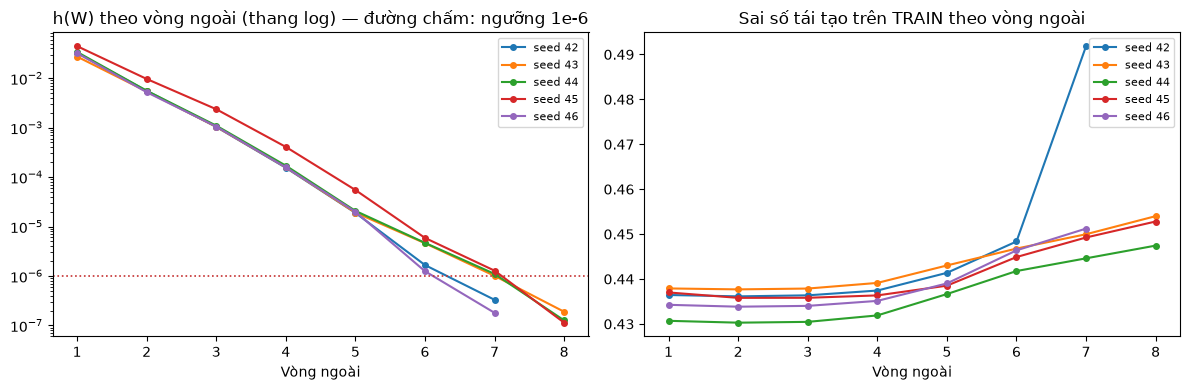

Bảng chọn ngưỡng tau trên VALIDATION — seed 42:


,tau,Edges,Cut_for_cycle,T->Y_forced,Val_LogLik,Pa(Y)
0,0.1,8,[],False,-2251.149676,"[T, Z1, Z2, Z3, Z5]"
1,0.2,7,[],False,-2254.787235,"[T, Z1, Z2, Z3, Z5]"
2,0.3,5,[],False,-2266.001516,"[T, Z2, Z3, Z5]"
3,0.5,3,[],False,-2279.091038,"[T, Z3, Z5]"
4,0.8,1,[],True,-2321.204896,[T]


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for s in SEEDS:
    k = np.arange(1, len(H2[s]['h_history']) + 1)
    ax1.semilogy(k, H2[s]['h_history'], marker='o', ms=4, label=f'seed {s}')
    ax2.plot(k, H2[s]['recon_history'], marker='o', ms=4, label=f'seed {s}')
ax1.axhline(1e-6, color='#c53030', ls=':', lw=1.2)
ax1.set_title('h(W) theo vòng ngoài (thang log) — đường chấm: ngưỡng 1e-6')
ax2.set_title('Sai số tái tạo trên TRAIN theo vòng ngoài')
for ax in (ax1, ax2):
    ax.set_xlabel('Vòng ngoài')
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print('Bảng chọn ngưỡng tau trên VALIDATION — seed 42:')
display(pd.DataFrame(H2[42]['tau_table']))

## 3b. "Log" của B0 — không có epoch
$B_0$ không huấn luyện bằng gradient nên không có epoch hay loss theo thời gian. Quá trình của nó gồm: (1) HillClimb tìm DAG trên TRAIN với từng hàm điểm BIC, BDeu, K2; (2) khớp CPD BDeu (đếm tần suất có làm mịn) trên TRAIN; (3) chọn hàm điểm có log-likelihood cao nhất trên VALIDATION. Bảng dưới là "log" lựa chọn đó, đọc từ `artifacts/graphs/b0_dag_seed<s>.json`.

In [8]:
dong = []
for s in SEEDS:
    d = json.load(open(GRAPHS / f'b0_dag_seed{s}.json', encoding='utf-8'))
    for c in d['candidates']:
        dong.append({'seed': s, 'hàm_điểm': c['Score'], 'số_cạnh': c['Edges'], 'Val_LogLik': round(c['Val_LogLik'], 2),
                     'Pa(Y)': c['Pa(Y)'], 'được_chọn': '✔' if c['Score'] == d['score_selected_on_val'] else ''})
display(pd.DataFrame(dong))

,seed,hàm_điểm,số_cạnh,Val_LogLik,Pa(Y),được_chọn
0,42,BIC,9,-2211.11,"[T, Z3, Z5]",
1,42,BDeu,9,-2211.11,"[T, Z3, Z5]",
2,42,K2,11,-2208.37,"[T, Z2, Z3, Z5]",✔
3,43,BIC,9,-2192.21,"[T, Z3, Z5]",
4,43,BDeu,9,-2192.21,"[T, Z3, Z5]",
5,43,K2,10,-2188.36,"[T, Z2, Z3, Z5]",✔
6,44,BIC,9,-2173.88,"[T, Z3, Z5]",
7,44,BDeu,10,-2172.39,"[T, Z2, Z3, Z5]",
8,44,K2,11,-2172.20,"[T, Z2, Z3, Z5]",✔
9,45,BIC,9,-2192.76,"[T, Z3, Z5]",


## 4. Có overfit không? AUROC / log-loss trên TRAIN, VAL, TEST

In [9]:
ov = pd.read_csv(TABLES / 'Table_Overfit_Train_Val_Test.csv')
bang = ov.pivot_table(index='Model', columns='Tập', values=['AUROC', 'Accuracy', 'LogLoss'], aggfunc='mean').round(4)
bang = bang.reindex(columns=['TRAIN', 'VAL', 'TEST'], level=1)
display(bang)

es = pd.read_csv(TABLES / 'Table_H1_Early_Stopping.csv')
print('H1 có / không early stopping — trung bình 5 seed:')
display(es.groupby('Bản H1')[[c for c in es.columns if c.startswith(('AUROC', 'LogLoss', 'ATE'))]].mean().round(4))

AUROC                 Accuracy                 LogLoss                
Tập     TRAIN     VAL    TEST    TRAIN     VAL    TEST   TRAIN     VAL    TEST
Model                                                                         
B0     0.8020  0.8000  0.7996   0.7389  0.7423  0.7442  0.4974  0.5024  0.4995
H1     0.8014  0.8004  0.8012   0.7382  0.7419  0.7365  0.4996  0.4995  0.4987
H2     0.8117  0.8064  0.8034   0.7500  0.7555  0.7494  0.4893  0.5029  0.5086

H1 có / không early stopping — trung bình 5 seed:


,AUROC_TRAIN,LogLoss_TRAIN,AUROC_VAL,LogLoss_VAL,AUROC_TEST,LogLoss_TEST,ATE_TEST
Bản H1,,,,,,,
Có early stopping,0.8014,0.4996,0.8004,0.4995,0.8012,0.4987,0.2374
Không early stopping,0.8018,0.4984,0.7988,0.5037,0.7992,0.5014,0.2355
